# Argos · Notebook 03 — Regressão: quanto o produtor deve colher por hectare?
**Pergunta:** com o clima do ano e o histórico do município, qual o rendimento esperado de milho, em kg/ha?

**Modelo:** Regressão Linear (`LinearRegression`), comparada com um baseline simples. **Alvo:** `rend_kg_ha`.

| Etapa | Notebook |
|---|---|
| Coleta e montagem do dataset | 01_coleta_e_preparo |
| Análise exploratória (EDA) | 02_eda |
| Preparação, treino e avaliação da regressão | 03_regressao (este) |
| Preparação, treino e avaliação da classificação | 04_classificacao |
| Exportação dos modelos (.joblib) | final do 03 e do 04 |
| API REST em Flask | api/api.py |

No final deste notebook, o modelo é salvo para ser usado pela API na rota `POST /api/v1/produtividade`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("scikit-learn", sklearn.__version__)

SEED = 2279
FONTE = "Fonte: IBGE/SIDRA (PAM, tabela 1612), Open-Meteo Historical e NOAA CPC (ONI). Elaboração do grupo."
df = pd.read_csv(Path("../dados/dataset_argos.csv"), encoding="utf-8")

# decisão da EDA (notebook 02): temp_media sai por colinearidade com temp_max_media (r = 0,99)
COLUNAS_MODELO = ["chuva_total_mm", "temp_max_media", "dias_acima_35", "maior_seq_seca",
                  "oni", "regiao_sul", "media_5a"]
ALVO = "rend_kg_ha"

treino = df[df["ano"] <= 2019].sort_values(["ano", "cd_municipio"]).reset_index(drop=True)
teste = df[df["ano"] >= 2020].sort_values(["ano", "cd_municipio"]).reset_index(drop=True)

X_treino, y_treino = treino[COLUNAS_MODELO].to_numpy(), treino[ALVO].to_numpy()
X_teste, y_teste = teste[COLUNAS_MODELO].to_numpy(), teste[ALVO].to_numpy()

print(f"Treino: {len(treino)} linhas ({treino['ano'].min()}–{treino['ano'].max()})")
print(f"Teste:  {len(teste)} linhas ({teste['ano'].min()}–{teste['ano'].max()})")

def br(valor):
    return f"{valor:,.0f}".replace(",", ".")

def rodape(fig):
    fig.text(0.01, -0.03, FONTE, fontsize=8, ha="left")

scikit-learn 1.9.1
Treino: 300 linhas (2010–2019)
Teste:  150 linhas (2020–2024)


**Por que separar por ano, e não por sorteio.** O treino tem os anos de 2010 a 2019 (300 linhas), e o teste tem os anos de 2020 a 2024 (150 linhas). No Argos, o modelo vai ser usado para prever safras futuras com base nas passadas. Se sorteássemos as linhas com `train_test_split`, o treino teria anos como 2022 e o teste teria anos como 2015, e o modelo estaria "vendo o futuro"; o resultado no teste sairia melhor do que seria na vida real. Também convertemos os dados para `numpy` (`.to_numpy()`), para que a ordem das colunas fique definida só pela lista `COLUNAS_MODELO`, que vai junto com o modelo para a API.

## 1. Baseline: "este ano vai ser igual à média dos últimos 5"
Antes de treinar, definimos uma regra simples para servir de comparação: prever que o rendimento do ano será igual à `media_5a`. É o que alguém diria sem olhar o clima. Se a Regressão Linear não fizer melhor que isso, o clima não está ajudando na previsão.

In [2]:
def metricas(real, previsto):
    return {"MAE (kg/ha)": mean_absolute_error(real, previsto),
            "RMSE (kg/ha)": np.sqrt(mean_squared_error(real, previsto)),
            "R²": r2_score(real, previsto)}

base_treino = treino["media_5a"].to_numpy()
base_teste = teste["media_5a"].to_numpy()

pd.DataFrame({"Baseline · treino": metricas(y_treino, base_treino),
              "Baseline · teste": metricas(y_teste, base_teste)}).T.round(3)

,MAE (kg/ha),RMSE (kg/ha),R²
Baseline · treino,898.233,1255.357,0.779
Baseline · teste,1152.019,1576.803,0.544


## 2. Padronização e treino
O `StandardScaler` deixa cada variável com média 0 e desvio padrão 1. Ele calcula a média e o desvio só com os dados de treino (`fit_transform`) e aplica os mesmos valores no teste (`transform`). Se o teste entrasse nesse cálculo, informação do futuro entraria no treino. Na Regressão Linear, a padronização não muda as previsões, mas deixa os coeficientes comparáveis: cada um passa a dizer quantos kg/ha a previsão muda quando a variável aumenta 1 desvio padrão.

In [3]:
scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)
X_teste_esc = scaler.transform(X_teste)

modelo = LinearRegression()
modelo.fit(X_treino_esc, y_treino)

prev_treino = modelo.predict(X_treino_esc)
prev_teste = modelo.predict(X_teste_esc)
print("Intercepto (β0):", round(modelo.intercept_, 1), "kg/ha")

Intercepto (β0): 3632.6 kg/ha


## 3. Métricas: modelo × baseline, no treino e no teste

,MAE (kg/ha),RMSE (kg/ha),R²
Baseline · treino,898.233,1255.357,0.779
Regressão Linear · treino,806.056,1130.748,0.821
Baseline · teste,1152.019,1576.803,0.544
Regressão Linear · teste,1198.961,1605.359,0.527


No teste, o modelo erra em média 1.199 kg/ha e o baseline erra 1.152 kg/ha (+4.1%).


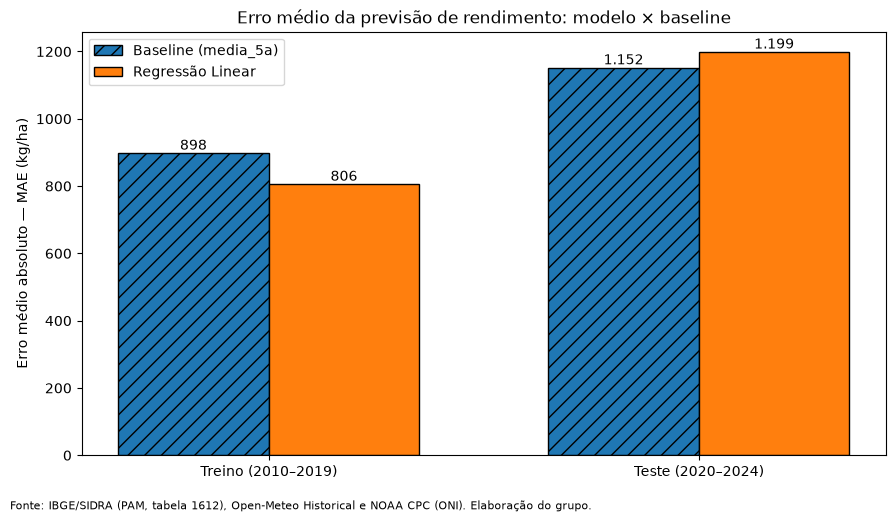

In [4]:
resultados = pd.DataFrame({
    "Baseline · treino": metricas(y_treino, base_treino),
    "Regressão Linear · treino": metricas(y_treino, prev_treino),
    "Baseline · teste": metricas(y_teste, base_teste),
    "Regressão Linear · teste": metricas(y_teste, prev_teste),
}).T
display(resultados.round(3))

mae_teste_modelo = resultados.loc["Regressão Linear · teste", "MAE (kg/ha)"]
mae_teste_base = resultados.loc["Baseline · teste", "MAE (kg/ha)"]
print(f"No teste, o modelo erra em média {br(mae_teste_modelo)} kg/ha e o baseline erra {br(mae_teste_base)} kg/ha "
      f"({(mae_teste_modelo / mae_teste_base - 1):+.1%}).")

fig, eixo = plt.subplots(figsize=(9, 5))
posicoes = np.arange(2)
largura = 0.35
valores_base = [resultados.loc["Baseline · treino", "MAE (kg/ha)"], mae_teste_base]
valores_modelo = [resultados.loc["Regressão Linear · treino", "MAE (kg/ha)"], mae_teste_modelo]
barras_b = eixo.bar(posicoes - largura / 2, valores_base, largura, hatch="//", edgecolor="black", label="Baseline (media_5a)")
barras_m = eixo.bar(posicoes + largura / 2, valores_modelo, largura, edgecolor="black", label="Regressão Linear")
eixo.bar_label(barras_b, labels=[br(v) for v in valores_base])
eixo.bar_label(barras_m, labels=[br(v) for v in valores_modelo])
eixo.set_xticks(posicoes, ["Treino (2010–2019)", "Teste (2020–2024)"])
eixo.set_ylabel("Erro médio absoluto — MAE (kg/ha)")
eixo.set_title("Erro médio da previsão de rendimento: modelo × baseline")
eixo.legend()
rodape(fig)
plt.tight_layout()
plt.show()

**Interpretação.**
- No treino, o modelo ganha do baseline: erro médio (MAE) de 806 kg/ha, contra 898 (cerca de 10% menor), e R² de 0,821, contra 0,779.
- No teste, o modelo perde por pouco: MAE de 1.199 contra 1.152 kg/ha (4,1% maior), RMSE de 1.605 contra 1.577 e R² de 0,527 contra 0,544.
- O erro sobe de 806 no treino para 1.199 no teste. Isso pode ser overfitting (o modelo "decorou" o treino) ou uma mudança nos próprios dados (os anos de teste são diferentes). A validação da próxima seção ajuda a separar as duas coisas. Não é underfitting, porque no treino o modelo explica 82% da variação do rendimento.

## 4. Validação por blocos de anos (dentro do treino)
Usamos o `KFold` com 5 partes, sem embaralhar. Como o treino está ordenado por ano, cada parte é um bloco de 2 anos seguidos. Em cada rodada, o modelo treina com 8 anos e é testado nos 2 que ficaram de fora, sempre comparado com o baseline. Os anos de 2020 a 2024 não entram nesta etapa.

In [5]:
linhas = []
for treino_idx, valid_idx in KFold(n_splits=5).split(X_treino):
    escala = StandardScaler().fit(X_treino[treino_idx])
    lr = LinearRegression().fit(escala.transform(X_treino[treino_idx]), y_treino[treino_idx])
    previsto = lr.predict(escala.transform(X_treino[valid_idx]))
    anos = treino.loc[valid_idx, "ano"]
    linhas.append({"anos validados": f"{anos.min()}–{anos.max()}",
                   "MAE modelo (kg/ha)": mean_absolute_error(y_treino[valid_idx], previsto),
                   "MAE baseline (kg/ha)": mean_absolute_error(y_treino[valid_idx], base_treino[valid_idx])})

blocos = pd.DataFrame(linhas)
blocos["modelo ganhou?"] = np.where(blocos["MAE modelo (kg/ha)"] < blocos["MAE baseline (kg/ha)"], "sim", "não")
display(blocos.round(1))
print(f"Média dos blocos: modelo {br(blocos['MAE modelo (kg/ha)'].mean())} × baseline {br(blocos['MAE baseline (kg/ha)'].mean())} kg/ha")

,anos validados,MAE modelo (kg/ha),MAE baseline (kg/ha),modelo ganhou?
0,2010–2011,717.0,757.3,sim
1,2012–2013,920.6,952.7,sim
2,2014–2015,646.9,815.6,sim
3,2016–2017,1039.8,1107.5,sim
4,2018–2019,914.0,858.2,não


Média dos blocos: modelo 848 × baseline 898 kg/ha


**Interpretação.** Em anos que não viu, mas dentro do período de 2010 a 2019, o modelo ganha do baseline em 4 dos 5 blocos (erro médio de 848 contra 898 kg/ha) e só perde em 2018–2019. Então ele não está apenas decorando o treino: o clima ajuda um pouco quando o ano é parecido com os que ele conhece. A piora no teste vem principalmente de 2020 a 2024 serem anos diferentes, com as secas de La Niña no Sul (notebook 02).

## 5. Resíduos no teste (erro = real − previsto)

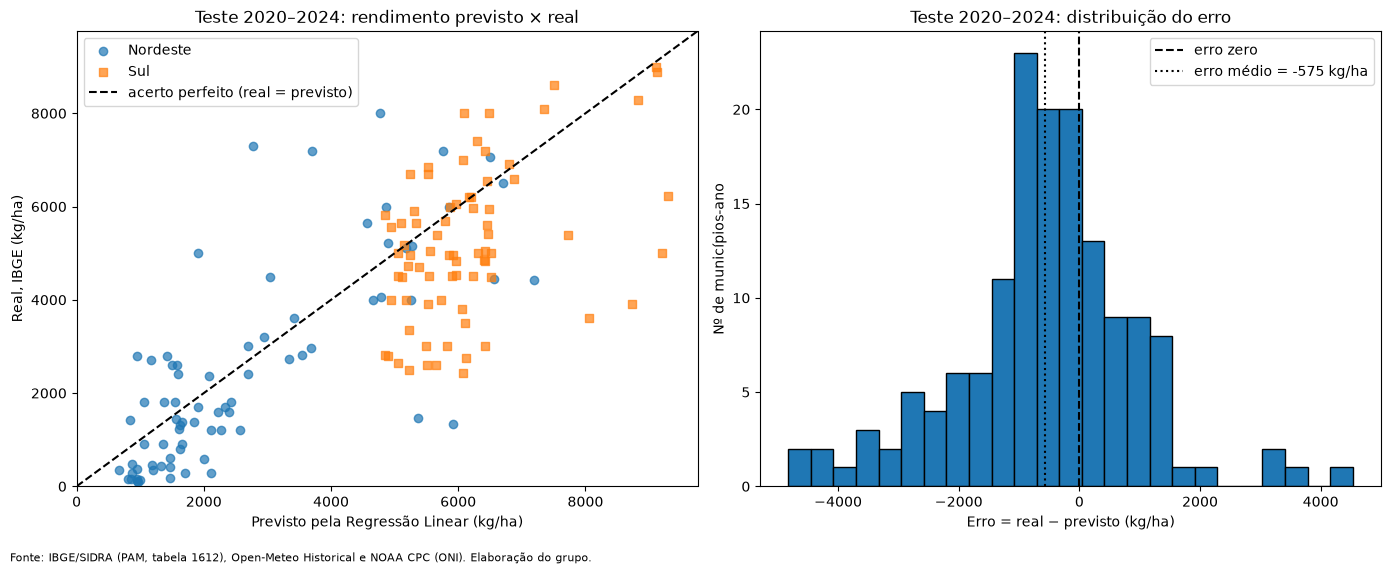

Erro médio: -575 kg/ha | o modelo previu acima do real em 69% das linhas
Correlação entre |erro| e valor previsto: 0.29


In [6]:
residuo = y_teste - prev_teste
eh_sul = teste["regiao_sul"].to_numpy() == 1

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, 5.5))
for mascara, marcador, nome in [(~eh_sul, "o", "Nordeste"), (eh_sul, "s", "Sul")]:
    eixo1.scatter(prev_teste[mascara], y_teste[mascara], marker=marcador, alpha=0.7, label=nome)
limite = max(prev_teste.max(), y_teste.max()) * 1.05
eixo1.plot([0, limite], [0, limite], color="black", linestyle="--", label="acerto perfeito (real = previsto)")
eixo1.set_xlim(0, limite)
eixo1.set_ylim(0, limite)
eixo1.set_title("Teste 2020–2024: rendimento previsto × real")
eixo1.set_xlabel("Previsto pela Regressão Linear (kg/ha)")
eixo1.set_ylabel("Real, IBGE (kg/ha)")
eixo1.legend()

eixo2.hist(residuo, bins=25, edgecolor="black")
eixo2.axvline(0, color="black", linestyle="--", label="erro zero")
eixo2.axvline(residuo.mean(), color="black", linestyle=":", label=f"erro médio = {br(residuo.mean())} kg/ha")
eixo2.set_title("Teste 2020–2024: distribuição do erro")
eixo2.set_xlabel("Erro = real − previsto (kg/ha)")
eixo2.set_ylabel("Nº de municípios-ano")
eixo2.legend()
rodape(fig)
plt.tight_layout()
plt.show()

print(f"Erro médio: {br(residuo.mean())} kg/ha | o modelo previu acima do real em {(residuo < 0).mean():.0%} das linhas")
print(f"Correlação entre |erro| e valor previsto: {np.corrcoef(np.abs(residuo), prev_teste)[0, 1]:.2f}")

**Interpretação.** O erro médio no teste é de −575 kg/ha, e o modelo previu acima do real em 69% das linhas, ou seja, ele foi otimista em 2020–2024. No gráfico da esquerda, a maioria dos pontos fica abaixo da linha tracejada, principalmente os do Sul. Também aparece um leve formato de funil: o erro tende a crescer quando o valor previsto é maior (correlação de 0,29). Faz sentido, porque errar 20% num município que colhe 9.000 kg/ha dá muito mais kg do que num que colhe 500. Uma alternativa vista em aula para esse caso é modelar o log do rendimento, e testamos isso na célula abaixo, usando só os blocos do treino.

In [7]:
mae_log = []
for treino_idx, valid_idx in KFold(n_splits=5).split(X_treino):
    escala = StandardScaler().fit(X_treino[treino_idx])
    lr_log = LinearRegression().fit(escala.transform(X_treino[treino_idx]), np.log1p(y_treino[treino_idx]))
    previsto = np.expm1(lr_log.predict(escala.transform(X_treino[valid_idx])))
    mae_log.append(mean_absolute_error(y_treino[valid_idx], previsto))
print(f"Validação por blocos (treino): log(y) = {br(np.mean(mae_log))} kg/ha × linear = {br(blocos['MAE modelo (kg/ha)'].mean())} kg/ha")

Validação por blocos (treino): log(y) = 1.590 kg/ha × linear = 848 kg/ha


**Interpretação.** Com `log(y)`, o erro médio nos blocos do treino sobe para cerca de 1.590 kg/ha, contra 848 do modelo normal. Ao voltar da escala de log para kg/ha, os erros nos municípios de rendimento alto ficam ainda maiores. Por isso mantivemos o modelo em kg/ha e registramos o funil como limitação. Essa escolha foi feita só com o treino, sem olhar o teste.

## 6. Onde o modelo erra: anos de quebra × anos normais

In [8]:
teste_av = teste.assign(previsto=prev_teste, residuo=residuo)

def resumo_erro(grupo):
    return pd.Series({"linhas": len(grupo),
                      "MAE modelo": mean_absolute_error(grupo[ALVO], grupo["previsto"]),
                      "MAE baseline": mean_absolute_error(grupo[ALVO], grupo["media_5a"]),
                      "erro médio": grupo["residuo"].mean()})

print("Por situação do ano:")
display(teste_av.groupby("quebra").apply(resumo_erro).rename(index={0: "sem quebra", 1: "quebra"}).round(0))
print("Por região:")
display(teste_av.groupby("regiao_sul").apply(resumo_erro).rename(index={0: "Nordeste", 1: "Sul"}).round(0))
print("Por ano:")
display(teste_av.groupby("ano").apply(resumo_erro).round(0))

Por situação do ano:


,linhas,MAE modelo,MAE baseline,erro médio
quebra,,,,
sem quebra,98.0,797.0,900.0,158.0
quebra,52.0,1956.0,1626.0,-1956.0


Por região:


,linhas,MAE modelo,MAE baseline,erro médio
regiao_sul,,,,
Nordeste,75.0,1024.0,895.0,-192.0
Sul,75.0,1373.0,1410.0,-958.0


Por ano:


,linhas,MAE modelo,MAE baseline,erro médio
ano,,,,
2020,30.0,1399.0,1446.0,90.0
2021,30.0,1507.0,1454.0,-1041.0
2022,30.0,1263.0,1132.0,-787.0
2023,30.0,877.0,966.0,-402.0
2024,30.0,949.0,762.0,-735.0


**Interpretação.**
- Nos anos sem quebra, o modelo ganha do baseline: MAE de 797 contra 900 kg/ha (98 linhas).
- Nos anos de quebra, ele perde bastante: 1.956 contra 1.626 kg/ha (52 linhas), e sempre prevê acima do real. O modelo aprendeu a prever um ano "típico", e a quebra é justamente o ano fora do comum.
- O pior ano é 2021 (erro médio de −1.041 kg/ha), quando 11 dos 15 municípios do Sul quebraram. No Sul, o erro médio é de −958 kg/ha; no Nordeste, de −192.

**O que isso significa para o Argos:** a regressão é útil para dizer quanto se colhe num ano normal, mas não avisa quando o ano vai ser ruim. Por isso o Argos também tem um modelo de classificação do risco de quebra (notebook 04), e no app os dois resultados aparecem juntos.

## 7. Coeficientes: o que mais pesa

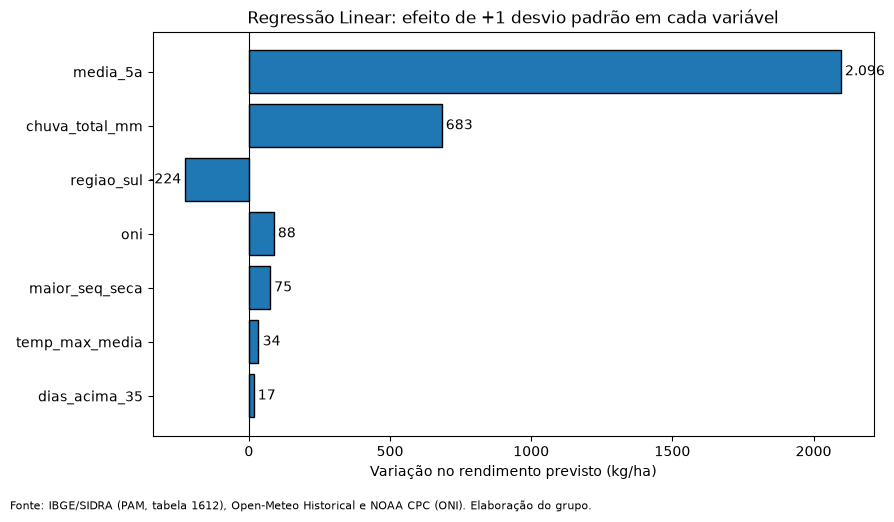

,coeficiente (kg/ha por 1 DP),1 desvio padrão no treino
chuva_total_mm,682.60,649.13
temp_max_media,33.84,2.83
dias_acima_35,16.77,25.34
maior_seq_seca,74.85,39.03
oni,87.76,0.60
regiao_sul,-224.48,0.50
media_5a,2096.43,2248.69


In [9]:
coeficientes = pd.Series(modelo.coef_, index=COLUNAS_MODELO).sort_values(key=abs)

fig, eixo = plt.subplots(figsize=(9, 5))
barras = eixo.barh(coeficientes.index, coeficientes.values, edgecolor="black")
eixo.bar_label(barras, labels=[br(v) for v in coeficientes.values], padding=3)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set_title("Regressão Linear: efeito de +1 desvio padrão em cada variável")
eixo.set_xlabel("Variação no rendimento previsto (kg/ha)")
rodape(fig)
plt.tight_layout()
plt.show()

pd.DataFrame({"coeficiente (kg/ha por 1 DP)": modelo.coef_, "1 desvio padrão no treino": scaler.scale_},
             index=COLUNAS_MODELO).round(2)

**Interpretação.** A variável que mais pesa é o histórico: quando a `media_5a` aumenta 1 desvio padrão (cerca de 2.250 kg/ha), a previsão sobe 2.096 kg/ha. Em seguida vem a chuva: 1 desvio padrão a mais (cerca de 650 mm) soma 683 kg/ha. A `regiao_sul` ficou com coeficiente negativo (−224), mesmo o Sul colhendo mais. Isso não quer dizer que estar no Sul prejudica: região, chuva e histórico andam juntos (correlações de 0,87 e 0,81 no notebook 02), então o modelo divide o efeito entre eles, e a região acaba só ajustando o que as outras duas já explicaram. As demais variáveis têm efeito pequeno (`oni` +88, `maior_seq_seca` +75, `temp_max_media` +34, `dias_acima_35` +17), e algumas com sinal diferente do esperado, já que uma sequência seca maior deveria diminuir o rendimento. Isso confirma o que vimos na EDA: o clima do ano inteiro tem um sinal fraco. Por isso tratamos esses coeficientes como associações, e não como causa e efeito.

## 8. Conclusão e limitações
- O modelo ganha do baseline em anos parecidos com os do treino (4 de 5 blocos da validação e os anos sem quebra do teste), mas perde por pouco no teste como um todo (MAE de 1.199 contra 1.152 kg/ha), por causa dos anos de quebra de 2020 a 2024.
- Mesmo assim, é o modelo que vai para a API: ele usa o clima do ano (o baseline não muda com a chuva) e, no app, aparece junto com o risco de quebra, que é o alerta principal.
- Limitações: clima resumido por ano civil, que é grosseiro para a safra; só 300 linhas de treino; colinearidade entre região, chuva e histórico; anos de perda total que ficaram fora da amostra (notebook 01); e a necessidade de treinar o modelo de novo a cada safra.

## 9. Exportação do modelo (.joblib)
Usamos o `joblib.dump` para salvar, num único arquivo, tudo o que a API precisa para prever igual a este notebook: o modelo treinado, o scaler (com a média e o desvio do treino), a lista de colunas na ordem certa e o nome curto que aparece no card do front. A API só precisa carregar esse arquivo com `joblib.load`, sem nenhum número escrito à mão no código.

In [10]:
metricas_teste = {}
for chave, valor in metricas(y_teste, prev_teste).items():
    metricas_teste[chave] = round(float(valor), 3)

pacote = {
    "nome": "linreg_v1",
    "modelo": modelo,
    "scaler": scaler,
    "colunas": COLUNAS_MODELO,
    "alvo": ALVO,
    "versao_sklearn": sklearn.__version__,
    "metricas_teste": metricas_teste,
}

PASTA_MODELOS = Path("../modelos")
PASTA_MODELOS.mkdir(exist_ok=True)
ARQ_MODELO = PASTA_MODELOS / "regressao_v1.joblib"
joblib.dump(pacote, ARQ_MODELO)
print("Salvo:", ARQ_MODELO, f"({ARQ_MODELO.stat().st_size / 1024:.1f} KB)")

Salvo: ..\modelos\regressao_v1.joblib (1.4 KB)


**Teste do arquivo salvo.** Carregamos o `.joblib` do disco e fazemos a previsão do mesmo jeito que a API vai fazer: partimos de um JSON com os 8 campos combinados com o front, montamos a linha na ordem de `pacote["colunas"]`, aplicamos o `scaler.transform` e só depois chamamos o `predict`. O campo `temp_media` vem no JSON, mas é ignorado, porque não está nas colunas do modelo.

In [11]:
carregado = joblib.load(ARQ_MODELO)
print("Chaves do pacote:", list(carregado.keys()))
print("Modelo:", carregado["nome"], "| treinado com scikit-learn", carregado["versao_sklearn"], "| colunas:", carregado["colunas"])

ENTRADAS_CONTRATO = ["chuva_total_mm", "temp_media", "temp_max_media", "dias_acima_35",
                     "maior_seq_seca", "oni", "regiao_sul", "media_5a"]

def prever_como_api(pacote, entrada_json):
    linha = []
    for coluna in pacote["colunas"]:
        linha.append(float(entrada_json[coluna]))
    linha_esc = pacote["scaler"].transform([linha])
    return round(float(pacote["modelo"].predict(linha_esc)[0]), 1)

for municipio, ano in [("Araci", 2023), ("Chapecó", 2020)]:
    real = df[(df["nm_municipio"] == municipio) & (df["ano"] == ano)].iloc[0]
    entrada_json = real[ENTRADAS_CONTRATO].to_dict()
    previsto = prever_como_api(carregado, entrada_json)
    print(f"{municipio} {ano}: kg_ha_previsto = {previsto} | real = {br(real[ALVO])} | media_5a = {br(real['media_5a'])}")

assert prever_como_api(carregado, real[ENTRADAS_CONTRATO].to_dict()) == round(float(modelo.predict(scaler.transform([real[COLUNAS_MODELO].to_numpy()]))[0]), 1)
print("O pacote carregado do disco prevê igual ao modelo da memória.")

Chaves do pacote: ['nome', 'modelo', 'scaler', 'colunas', 'alvo', 'versao_sklearn', 'metricas_teste']
Modelo: linreg_v1 | treinado com scikit-learn 1.9.1 | colunas: ['chuva_total_mm', 'temp_max_media', 'dias_acima_35', 'maior_seq_seca', 'oni', 'regiao_sul', 'media_5a']
Araci 2023: kg_ha_previsto = 959.2 | real = 103 | media_5a = 670
Chapecó 2020: kg_ha_previsto = 9125.1 | real = 8.880 | media_5a = 9.000
O pacote carregado do disco prevê igual ao modelo da memória.


**Interpretação.** O modelo carregado do disco prevê exatamente o mesmo valor que o modelo em memória. Para Chapecó em 2020 (ano normal), a previsão é de cerca de 9.125 kg/ha, contra 8.880 reais, um erro de menos de 3%. Para Araci em 2023 (ano seco), a previsão é de cerca de 959 kg/ha, contra 103 reais. É o mesmo comportamento da seção 6: em ano de quebra, a regressão é otimista. Na demonstração, mostramos o rendimento previsto como o de um "ano típico", e o aviso de perigo fica com o risco de quebra do notebook 04.